# Testing nested clusters for stability

Nested clustering joins the weaker groups, searches inside them again, and keeps the replacement only when average group quality improves:

$$
q_g=\frac{\overline s_g}{\operatorname{sd}(s_g)},
\qquad
\mathcal R=\{g:q_g<\overline q\},
\qquad
\text{accept a new split only if }\overline q_{\mathrm{new}}>\overline q_{\mathcal R}.
$$

Here, $g$ labels a cluster; $s_g$ is its vector of silhouettes; $\overline s_g$ and $\operatorname{sd}(s_g)$ are its mean and spread. $q_g$ is cluster quality; $\overline q$ is the mean across clusters; $\mathcal R$ is the set selected for another search; $\overline q_{\mathrm{new}},\overline q_{\mathcal R}$ compare new and old quality.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score, silhouette_samples
from sklearn.utils import check_random_state

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.cluster.clustering import cluster_k_means_base, cluster_k_means_top, random_block_correlation
from RiskLabAI.ensemble.bagging_classifier_accuracy import bagging_classifier_accuracy
from RiskLabAI.ensemble.empirical_bagging_accuracy import BaggingClassifierAccuracy, calculate_bootstrap_accuracy

warnings.filterwarnings("ignore", message="X has feature names")

FIGURES = ROOT / "outputs" / "figures" / "15_predictor_clustering"
TABLES = ROOT / "outputs" / "tables" / "15_predictor_clustering"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

selected_features = ["Food", "Beer", "Hshld", "Oil", "Coal", "Mines", "Hardw", "Softw", "Chips", "Banks", "Insur", "Fin"]
trailing_returns = industry_returns[selected_features].rolling(5).sum().shift(1)
market_direction = (industry_returns.mean(axis=1) > 0).astype(int).rename("Market direction")
public_frame = pd.concat([trailing_returns, market_direction], axis=1).dropna()
public_x = public_frame[selected_features]
public_y = public_frame["Market direction"]
split_index = int(len(public_x) * 0.70)
public_x_train = public_x.iloc[:split_index]
public_y_train = public_y.iloc[:split_index]
public_x_test = public_x.iloc[split_index:]
public_y_test = public_y.iloc[split_index:]

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_cluster_table(frame, stem, caption, label):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    summary_columns = [column for column in frame.columns if column != "Industries"]
    headings = {
        "Cluster": "Cluster",
        "Size": "Size",
        "Mean silhouette": r"Mean $s$",
        "Minimum silhouette": r"Minimum $s$",
        "Quality": "Quality",
        "Mean within correlation": r"Mean $\rho$",
        "Mean within-cluster co-membership": "Mean joining frequency",
    }
    lines = [
        r"\begin{table}[H]",
        f"\\caption{{{caption}}}",
        f"\\label{{{label}}}",
        r"\centering",
        r"\small",
        r"\begin{tabular}{@{}" + "r" * len(summary_columns) + r"@{}}",
        r"\toprule",
        " & ".join(headings[column] for column in summary_columns) + r" \\",
        r"\midrule",
    ]
    for _, row in frame.iterrows():
        values = []
        for column in summary_columns:
            value = row[column]
            if column in {"Cluster", "Size"}:
                values.append(str(int(value)))
            else:
                values.append(f"{float(value):.6f}")
        lines.append(" & ".join(values) + r" \\")
    lines.extend([
        r"\bottomrule",
        r"\end{tabular}",
        r"\par\medskip",
        r"\begin{tabular}{@{}r p{0.82\textwidth}@{}}",
        r"\toprule",
        r"Cluster & Industries \\",
        r"\midrule",
    ])
    for _, row in frame.iterrows():
        members = str(row["Industries"]).replace("&", r"\&")
        lines.append(f"{int(row['Cluster'])} & {members}" + r" \\")
    lines.extend([r"\bottomrule", r"\end{tabular}", r"\end{table}"])
    (TABLES / f"{stem}.tex").write_text("\n".join(lines), encoding="utf-8")

def labels_from_clusters(columns, clusters):
    labels = pd.Series(index=columns, dtype="int64")
    for cluster_id, members in clusters.items():
        labels.loc[members] = int(cluster_id)
    return labels.astype(int)

def mean_within_correlation(correlation, members):
    if len(members) < 2:
        return 1.0
    block = correlation.loc[members, members].to_numpy()
    return block[np.triu_indices(len(members), 1)].mean()
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Nested Public Clusters

In [2]:
public_correlation = industry_returns.corr()
base_sorted, base_clusters, base_silhouette = cluster_k_means_base(public_correlation, max_clusters=12, iterations=20, random_state=13031)
nested_sorted, nested_clusters, nested_silhouette = cluster_k_means_top(public_correlation, max_clusters=12, iterations=20, random_state=13031)
base_labels = labels_from_clusters(public_correlation.columns, base_clusters)
nested_labels = labels_from_clusters(public_correlation.columns, nested_clusters)
nested_cluster_rows = []
for cluster_id, members in nested_clusters.items():
    nested_cluster_rows.append({"Cluster": int(cluster_id) + 1, "Size": len(members), "Mean silhouette": nested_silhouette.loc[members].mean(), "Minimum silhouette": nested_silhouette.loc[members].min(), "Quality": nested_silhouette.loc[members].mean() / nested_silhouette.loc[members].std() if nested_silhouette.loc[members].std() > 0 else np.inf, "Mean within correlation": mean_within_correlation(public_correlation, members), "Industries": ", ".join(members)})
nested_cluster_summary = pd.DataFrame(nested_cluster_rows).sort_values("Cluster")
save_cluster_table(nested_cluster_summary, "nested_cluster_summary", "Nested public industry clusters.", "tab:chapter13-nested-cluster-summary")
display(nested_cluster_summary.round(6))

,Cluster,Size,Mean silhouette,Minimum silhouette,Quality,Mean within correlation,Industries
0,1,2,0.296080,0.221033,2.789698,0.222696,"Gold, Coal"
1,2,47,0.396057,-0.043343,2.554849,0.597059,"Agric, Food, Soda, Beer, Smoke, Toys, Fun, Boo..."


The co-membership matrix records how often two industries stay together, while adjusted Rand agreement compares two full partitions after removing chance agreement:

$$
M_{ij}=\frac{1}{B}\sum_{b=1}^{B}\mathbf 1\!\left\{z_i^{(b)}=z_j^{(b)}\right\},
\qquad
\operatorname{ARI}
=\frac{\sum_{gh}{n_{gh}\choose2}-\dfrac{\sum_g{a_g\choose2}\sum_h{b_h\choose2}}{{n\choose2}}}
{\dfrac12\!\left[\sum_g{a_g\choose2}+\sum_h{b_h\choose2}\right]-\dfrac{\sum_g{a_g\choose2}\sum_h{b_h\choose2}}{{n\choose2}}}.
$$

Here, $B$ is the number of resampled histories; $z_i^{(b)}$ is industry $i$'s cluster label in repetition $b$; $M_{ij}\in[0,1]$ is their joining frequency. $n_{gh}$ counts items shared by cluster $g$ in one partition and $h$ in the other; $a_g,b_h$ are cluster sizes; $n$ is item count; ${m\choose2}$ counts pairs; ARI is adjusted Rand agreement.

## Circular Block Resampling

,Quantity,Value
0,Resampled histories,24
1,Block length in days,20
2,Reference clusters,2
3,Mean resampled clusters,2.458333
4,Minimum adjusted Rand agreement,0.088528
5,Mean adjusted Rand agreement,0.220271
6,Maximum adjusted Rand agreement,1
7,Mean resampled silhouette,0.274436


,Cluster,Size,Mean within-cluster co-membership,Industries
0,1,2,0.958333,"Gold, Coal"
1,2,47,0.645313,"Agric, Food, Soda, Beer, Smoke, Toys, Fun, Boo..."


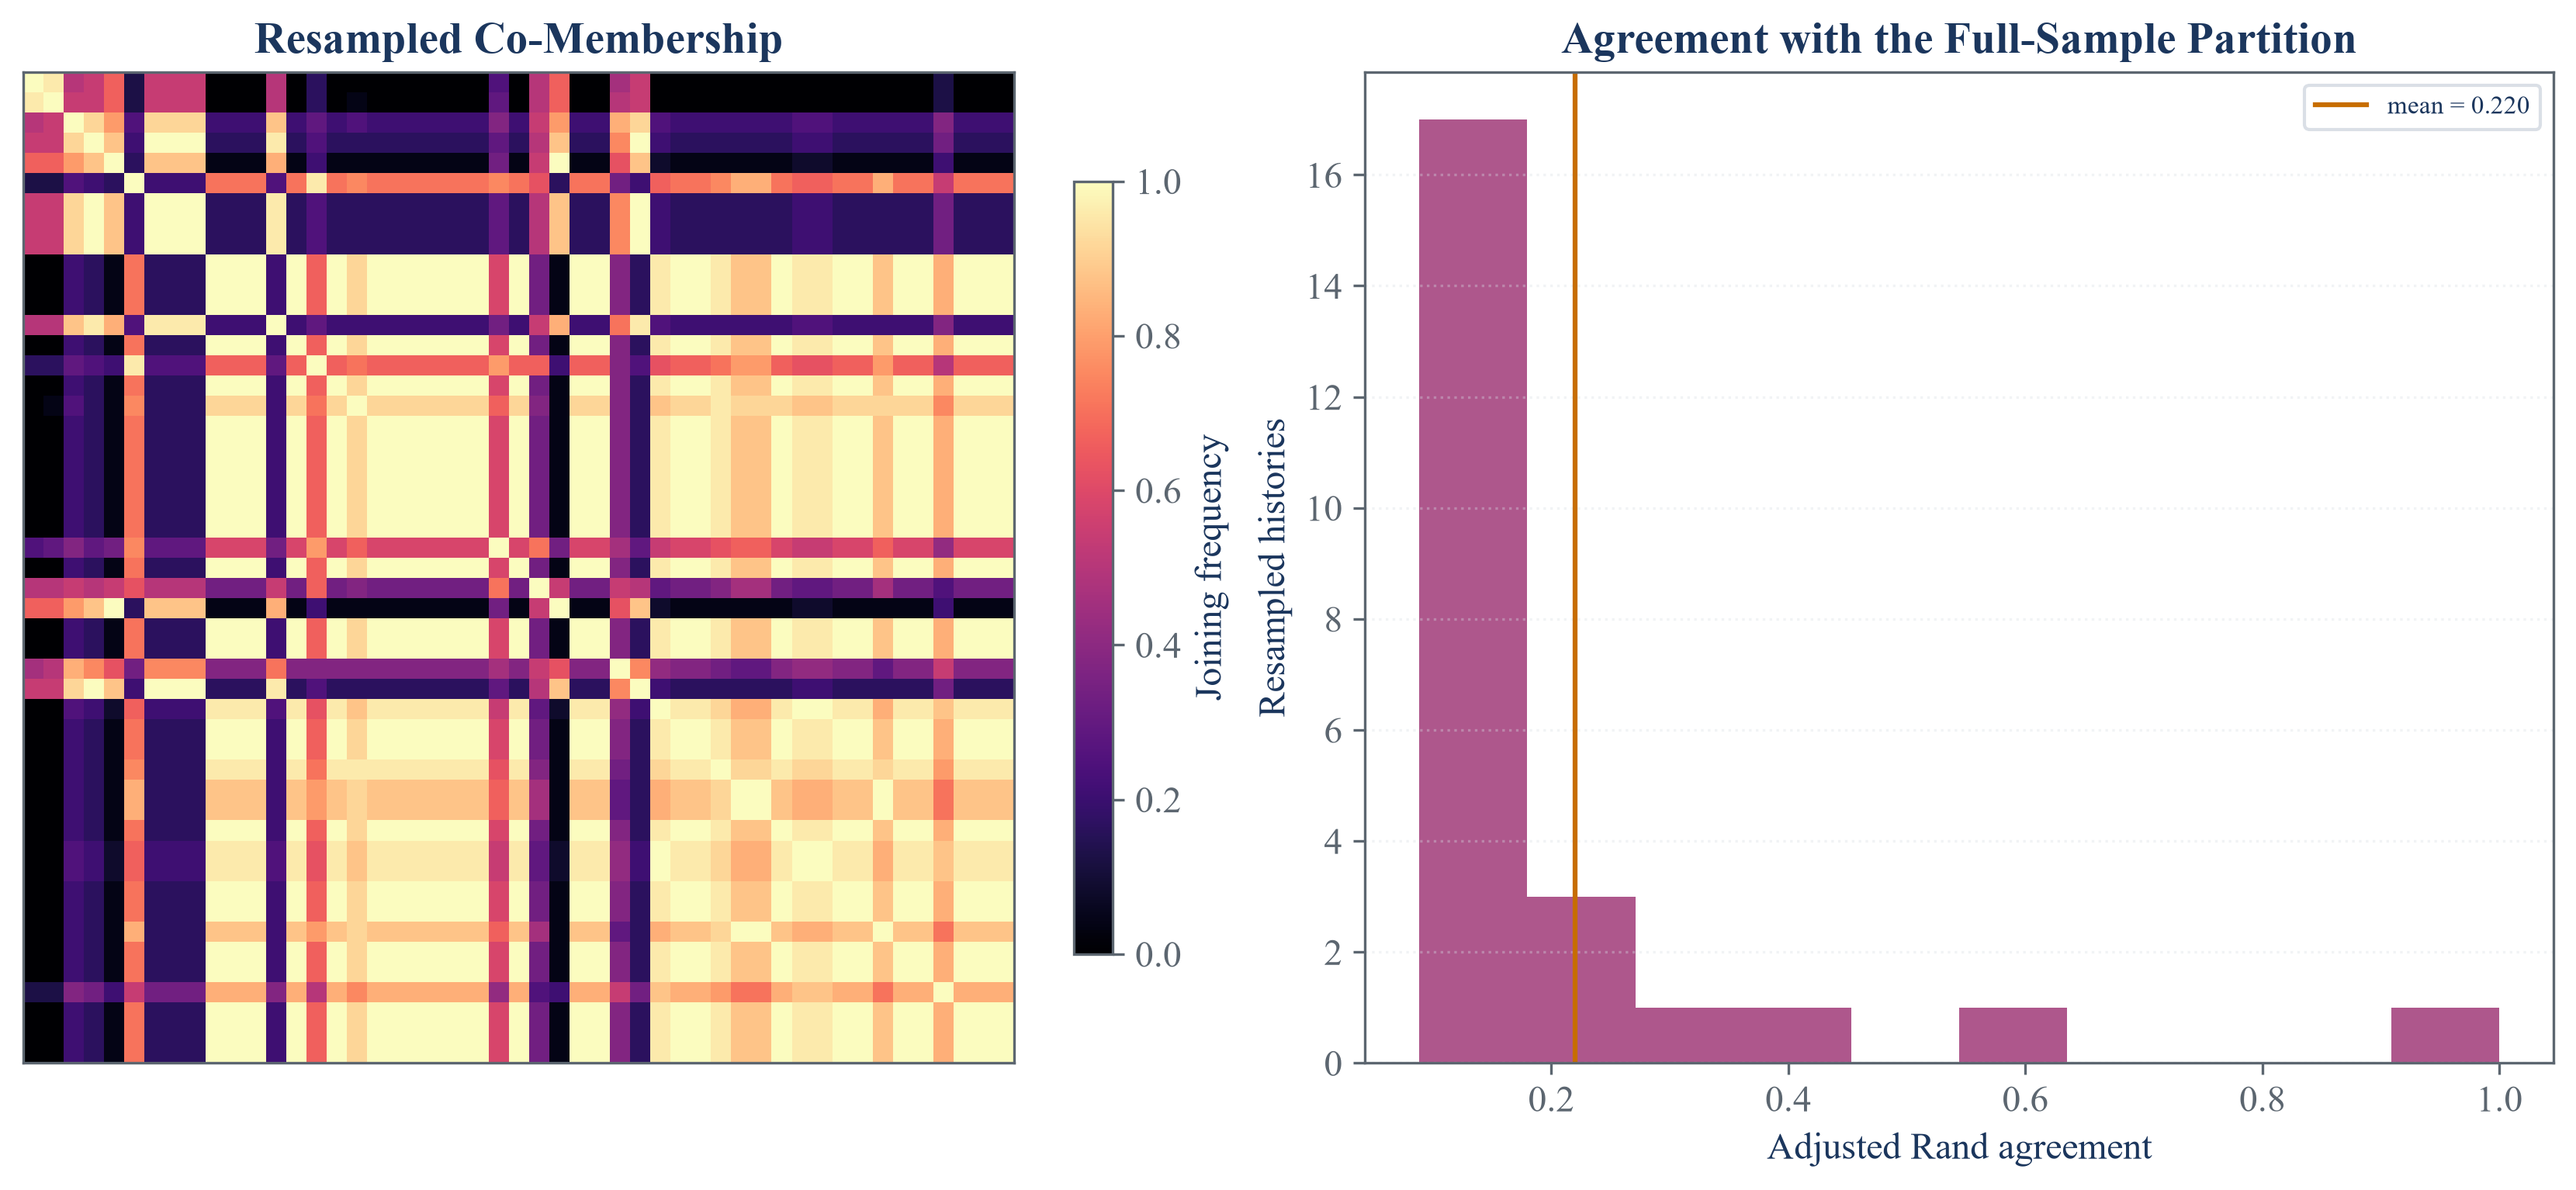

In [3]:
def circular_block_sample(frame, block_length, rng):
    block_count = int(np.ceil(len(frame) / block_length))
    starts = rng.integers(0, len(frame), block_count)
    positions = np.concatenate([(start + np.arange(block_length)) % len(frame) for start in starts])[:len(frame)]
    return frame.iloc[positions]

stability_rng = np.random.default_rng(13032)
stability_runs = 24
block_length = 20
membership_sum = np.zeros((49, 49), dtype=float)
stability_rows = []
stability_label_vectors = []
for repetition in range(stability_runs):
    resampled_returns = circular_block_sample(industry_returns, block_length, stability_rng)
    resampled_correlation = resampled_returns.corr()
    _, current_clusters, current_silhouette = cluster_k_means_top(resampled_correlation, max_clusters=12, iterations=8, random_state=13100 + repetition)
    current_labels = labels_from_clusters(public_correlation.columns, current_clusters)
    stability_label_vectors.append(current_labels.to_numpy())
    membership_sum += (current_labels.to_numpy()[:, None] == current_labels.to_numpy()[None, :]).astype(float)
    stability_rows.append({"Repetition": repetition + 1, "Clusters": len(current_clusters), "Adjusted Rand agreement": adjusted_rand_score(nested_labels, current_labels), "Mean silhouette": current_silhouette.mean()})
public_stability_paths = pd.DataFrame(stability_rows)
public_membership = membership_sum / stability_runs
public_stability_summary = pd.DataFrame({
    "Quantity": ["Resampled histories", "Block length in days", "Reference clusters", "Mean resampled clusters", "Minimum adjusted Rand agreement", "Mean adjusted Rand agreement", "Maximum adjusted Rand agreement", "Mean resampled silhouette"],
    "Value": [stability_runs, block_length, len(nested_clusters), public_stability_paths["Clusters"].mean(), public_stability_paths["Adjusted Rand agreement"].min(), public_stability_paths["Adjusted Rand agreement"].mean(), public_stability_paths["Adjusted Rand agreement"].max(), public_stability_paths["Mean silhouette"].mean()],
})
save_table(public_stability_summary, "public_stability_summary", "Circular block-resampling stability of the public nested clusters.", "tab:chapter13-public-stability-summary", fit=False)
display(public_stability_summary)

public_stability_by_cluster = pd.DataFrame([
    {"Cluster": int(cluster_id) + 1, "Size": len(members), "Mean within-cluster co-membership": public_membership[np.ix_([public_correlation.index.get_loc(item) for item in members], [public_correlation.index.get_loc(item) for item in members])][np.triu_indices(len(members), 1)].mean() if len(members) > 1 else 1.0, "Industries": ", ".join(members)}
    for cluster_id, members in nested_clusters.items()
]).sort_values("Cluster")
save_cluster_table(public_stability_by_cluster, "public_stability_by_cluster", "Resampled joining frequency within each reference cluster.", "tab:chapter13-public-stability-by-cluster")
display(public_stability_by_cluster.round(6))

nested_order = [public_correlation.index.get_loc(item) for item in nested_sorted.index]
figure, axes = plt.subplots(1, 2, figsize=(11.8, 5.0), constrained_layout=True)
membership_image = axes[0].imshow(public_membership[np.ix_(nested_order, nested_order)], cmap="magma", vmin=0, vmax=1)
axes[0].set_title("Resampled Co-Membership")
axes[0].set_xticks([])
axes[0].set_yticks([])
figure.colorbar(membership_image, ax=axes[0], shrink=0.78, label="Joining frequency")
axes[1].hist(public_stability_paths["Adjusted Rand agreement"], bins=10, color=palette["violet"], alpha=0.85)
axes[1].axvline(public_stability_paths["Adjusted Rand agreement"].mean(), color=palette["amber"], linewidth=1.5, label=f"mean = {public_stability_paths['Adjusted Rand agreement'].mean():.3f}")
axes[1].set_title("Agreement with the Full-Sample Partition")
axes[1].set_xlabel("Adjusted Rand agreement")
axes[1].set_ylabel("Resampled histories")
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.35)
figure.savefig(FIGURES / "public_cluster_stability.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_cluster_stability.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_cluster_stability.png")))
plt.close(figure)

## Known Block Recovery

The controlled benchmark adds five known covariance blocks to a common component, then converts the result to correlation before hiding the original order:

$$
\Sigma=\operatorname{blockdiag}(\Sigma_1,\ldots,\Sigma_G)+\Sigma_m,
\qquad
R_{ij}=\frac{\Sigma_{ij}}{\sqrt{\Sigma_{ii}\Sigma_{jj}}},
\qquad
G=5.
$$

Here, $\Sigma_g$ is the covariance block for group $g$; $G=5$ is the known group count; $\operatorname{blockdiag}$ places blocks on the diagonal. $\Sigma_m$ is the shared component; $\Sigma$ is total covariance; $R_{ij}$ is correlation; $i,j$ label the $30$ controlled series; diagonal terms are variances.

,Repetition,True clusters,Base clusters,Nested clusters,Base adjusted Rand agreement,Nested adjusted Rand agreement
0,1,5,5,5,1,1
1,2,5,5,5,1,1
2,3,5,5,5,1,1
3,4,5,5,5,1,1
4,5,5,5,5,1,1
5,6,5,5,5,1,1
6,7,5,5,5,1,1
7,8,5,5,5,1,1
8,9,5,5,5,1,1
9,10,5,5,5,1,1


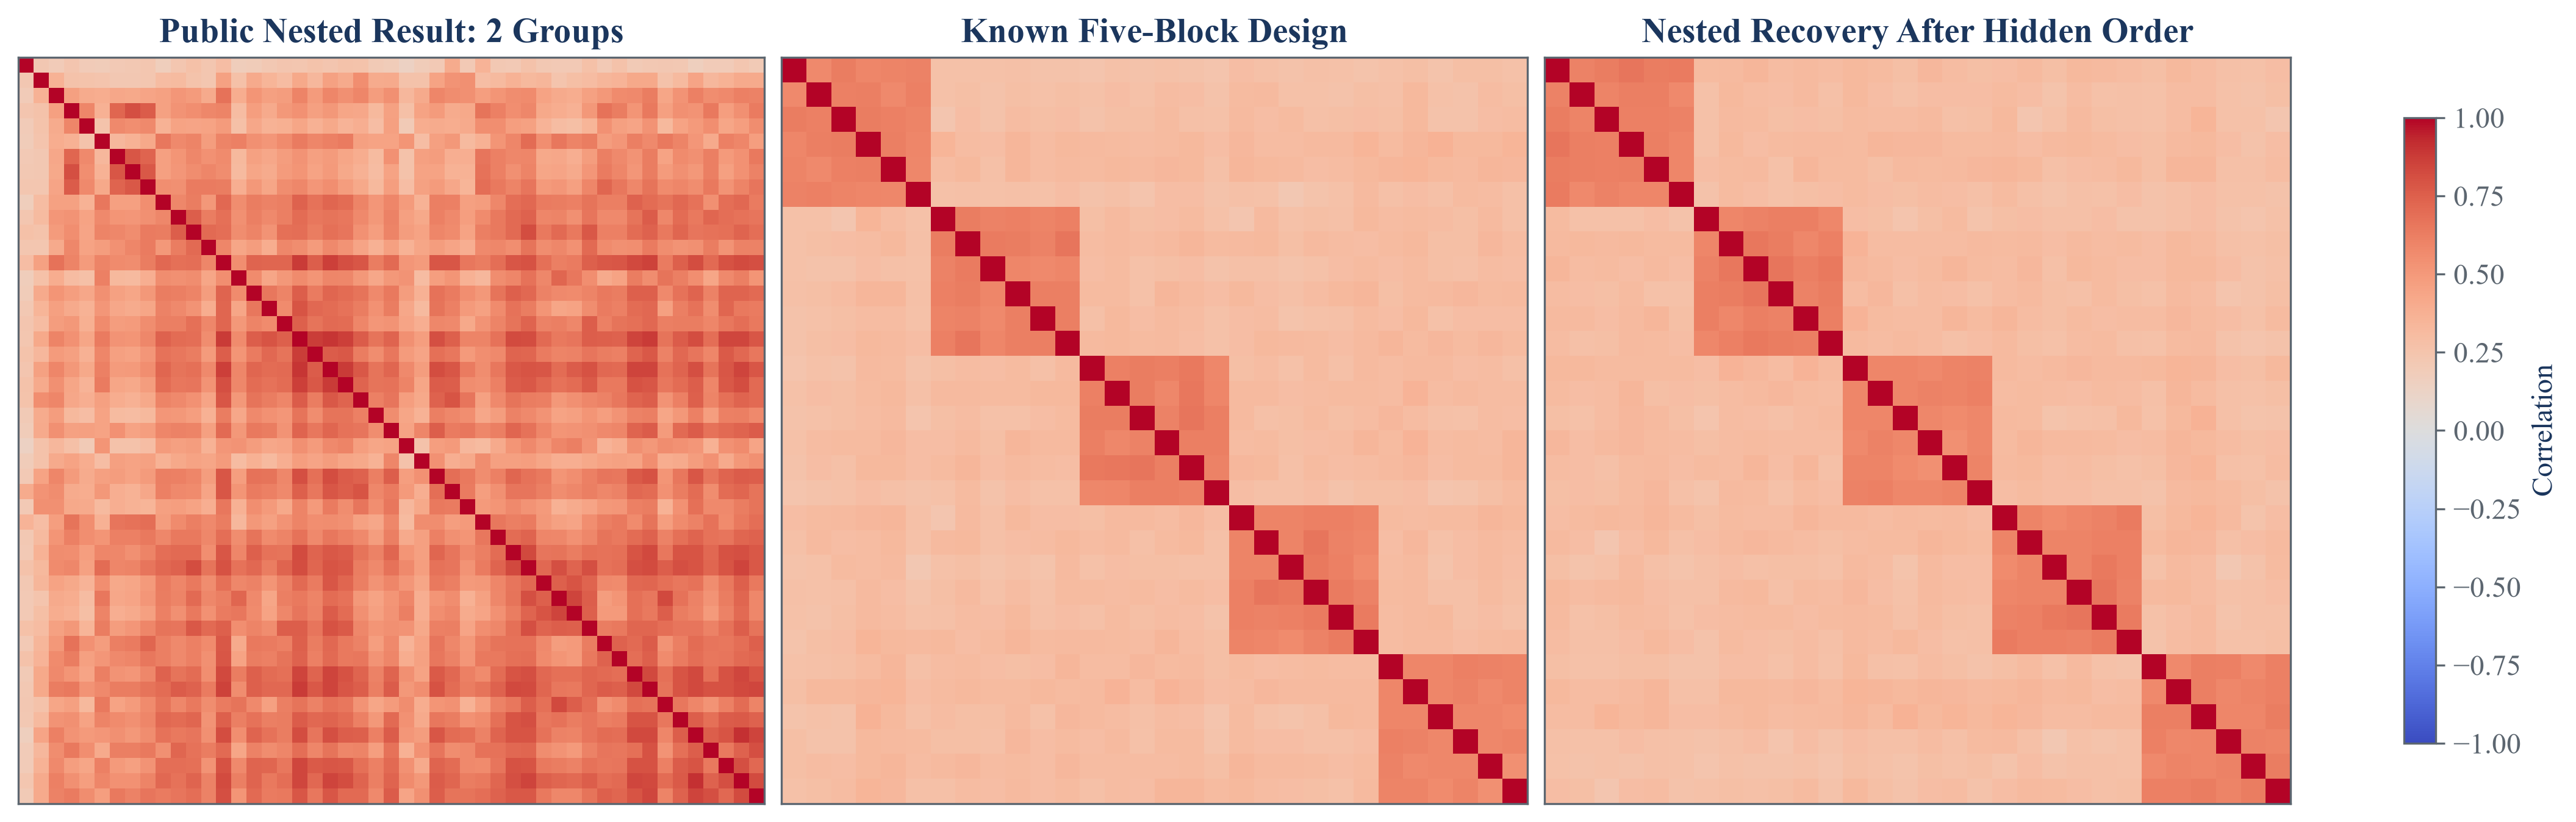

In [4]:
controlled_rows = []
controlled_example = None
controlled_example_sorted = None
for repetition in range(12):
    current_correlation = random_block_correlation(n_columns=30, n_blocks=5, block_size_min=6, random_state=13200 + repetition)
    original_names = [f"Series {index + 1:02d}" for index in range(30)]
    current_correlation.index = original_names
    current_correlation.columns = original_names
    true_labels = pd.Series(np.repeat(np.arange(5), 6), index=original_names)
    permutation = np.random.default_rng(13300 + repetition).permutation(original_names)
    hidden_correlation = current_correlation.loc[permutation, permutation]
    hidden_truth = true_labels.loc[permutation]
    _, current_base_clusters, _ = cluster_k_means_base(hidden_correlation, max_clusters=10, iterations=10, random_state=13400 + repetition)
    current_nested_sorted, current_nested_clusters, _ = cluster_k_means_top(hidden_correlation, max_clusters=10, iterations=10, random_state=13400 + repetition)
    current_base_labels = labels_from_clusters(hidden_correlation.columns, current_base_clusters)
    current_nested_labels = labels_from_clusters(hidden_correlation.columns, current_nested_clusters)
    controlled_rows.append({"Repetition": repetition + 1, "True clusters": 5, "Base clusters": len(current_base_clusters), "Nested clusters": len(current_nested_clusters), "Base adjusted Rand agreement": adjusted_rand_score(hidden_truth, current_base_labels), "Nested adjusted Rand agreement": adjusted_rand_score(hidden_truth, current_nested_labels)})
    if repetition == 0:
        controlled_example = current_correlation
        controlled_example_sorted = current_nested_sorted
controlled_recovery = pd.DataFrame(controlled_rows)
save_table(controlled_recovery, "controlled_recovery", "Known-block recovery over twelve fixed-seed correlation designs.", "tab:chapter13-controlled-recovery", fit=True)
display(controlled_recovery.round(6))

figure, axes = plt.subplots(1, 3, figsize=(14.0, 4.7), constrained_layout=True)
first_image = axes[0].imshow(nested_sorted.to_numpy(), cmap="coolwarm", vmin=-1.0, vmax=1.0)
axes[0].set_title(f"Public Nested Result: {len(nested_clusters)} Groups")
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[1].imshow(controlled_example.to_numpy(), cmap="coolwarm", vmin=-1.0, vmax=1.0)
axes[1].set_title("Known Five-Block Design")
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[2].imshow(controlled_example_sorted.to_numpy(), cmap="coolwarm", vmin=-1.0, vmax=1.0)
axes[2].set_title("Nested Recovery After Hidden Order")
axes[2].set_xticks([])
axes[2].set_yticks([])
figure.colorbar(first_image, ax=axes, shrink=0.75, label="Correlation")
figure.savefig(FIGURES / "public_nested_clusters.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "public_nested_clusters.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "public_nested_clusters.png")))
plt.close(figure)

## Tests

In [5]:
assert data_hash == EXPECTED_DATA_HASH
assert industry_returns.shape == (1760, 49)
assert public_correlation.shape == (49, 49)
assert 2 <= len(base_clusters) <= 12
assert 2 <= len(nested_clusters) <= 12
assert sum(len(members) for members in nested_clusters.values()) == 49
assert set(item for members in nested_clusters.values() for item in members) == set(public_correlation.columns)
assert nested_sorted.shape == (49, 49)
assert nested_silhouette.shape == (49,)
assert nested_silhouette.between(-1, 1).all()
assert nested_cluster_summary.shape == (len(nested_clusters), 7)
assert nested_cluster_summary["Size"].sum() == 49
assert nested_cluster_summary["Mean within correlation"].between(-1, 1).all()
assert public_stability_paths.shape == (24, 4)
assert public_stability_paths["Clusters"].between(2, 12).all()
assert public_stability_paths["Adjusted Rand agreement"].between(-1, 1).all()
assert public_stability_paths["Mean silhouette"].between(-1, 1).all()
assert public_membership.shape == (49, 49)
assert np.allclose(public_membership, public_membership.T)
assert np.allclose(np.diag(public_membership), 1.0)
assert public_membership.min() >= 0
assert public_membership.max() <= 1
assert public_stability_summary.shape == (8, 2)
assert public_stability_by_cluster.shape == (len(nested_clusters), 4)
assert public_stability_by_cluster["Mean within-cluster co-membership"].between(0, 1).all()
assert controlled_recovery.shape == (12, 6)
assert (controlled_recovery["True clusters"] == 5).all()
assert controlled_recovery["Base adjusted Rand agreement"].between(-1, 1).all()
assert controlled_recovery["Nested adjusted Rand agreement"].between(-1, 1).all()
assert controlled_recovery["Base adjusted Rand agreement"].mean() > 0.85
assert controlled_recovery["Nested adjusted Rand agreement"].mean() > 0.85
assert controlled_example.shape == (30, 30)
assert controlled_example_sorted.shape == (30, 30)
assert (FIGURES / "public_cluster_stability.pdf").is_file()
assert (FIGURES / "public_nested_clusters.pdf").is_file()
assert (TABLES / "nested_cluster_summary.tex").is_file()
assert (TABLES / "public_stability_summary.tex").is_file()
assert (TABLES / "public_stability_by_cluster.tex").is_file()
assert (TABLES / "controlled_recovery.tex").is_file()